# Urban Expansion in Rawalpindi District (2019-2025): Benchmarking ML Classifiers with Spatially-Honest Validation
**Author:** Malaika Noor  |  **Tools:** Google Earth Engine (Python API), scikit-learn

**Research question:** How much has built-up land grown in Rawalpindi district between 2019 and 2025, and how reliable is an ML land-cover map trained on *automatically generated* labels?

**What makes this more than a standard LULC project:**
- **No manual sampling or downloads:** training labels come from ESA WorldCover (2021); imagery is Sentinel-2, all inside Earth Engine.
- **Classifier benchmark** (Random Forest, Gradient Boosting, SVM) using **random CV vs spatial-block CV**, which shows how much ordinary validation overestimates accuracy because of spatial autocorrelation.
- **Independent cross-check** of built-up area against Google Dynamic World.
- **Change analysis** with a class-transition matrix and urban-growth statistics.

Run all cells top to bottom.

In [47]:
!pip -q install earthengine-api scikit-learn pandas matplotlib seaborn
import ee, os, io, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display

PROJECT = 'ee-nmalaika135'   # <- put your Earth Engine / Google Cloud project id here
try:
    ee.Initialize(project=PROJECT)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROJECT)
os.makedirs('results', exist_ok=True)

In [48]:
import ee; ee.Authenticate()

## 1. Study area and Sentinel-2 composites

In [49]:
gb = ee.FeatureCollection('WM/geoLab/geoBoundaries/600/ADM2').filter(ee.Filter.eq('shapeGroup', 'PAK'))
roi_fc = gb.filter(ee.Filter.eq('shapeName', 'Rawalpindi'))
print('Features found:', roi_fc.size().getInfo())
if roi_fc.size().getInfo() == 0:
    print([n for n in gb.aggregate_array('shapeName').getInfo() if 'awal' in n.lower()])
roi = roi_fc.geometry()

BANDS_RAW = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']

def mask_scl(img):
    scl = img.select('SCL')
    ok = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10)).And(scl.neq(11))
    return img.updateMask(ok)

def s2_composite(year):
    col = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED').filterBounds(roi)
           .filterDate(f'{year}-01-01', f'{year}-04-30')
           .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 40)).map(mask_scl))
    comp = col.select(BANDS_RAW).median().divide(10000)
    ndvi = comp.normalizedDifference(['B8', 'B4']).rename('NDVI')
    ndbi = comp.normalizedDifference(['B11', 'B8']).rename('NDBI')
    mndwi = comp.normalizedDifference(['B3', 'B11']).rename('MNDWI')
    return comp.addBands([ndvi, ndbi, mndwi]).clip(roi)

FEATS = BANDS_RAW + ['NDVI', 'NDBI', 'MNDWI']
comp = {y: s2_composite(y) for y in (2019, 2021, 2025)}

Features found: 1
Features found: 1


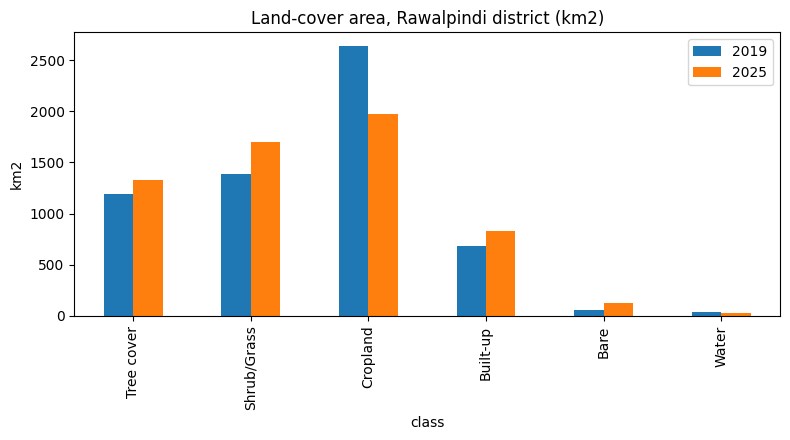

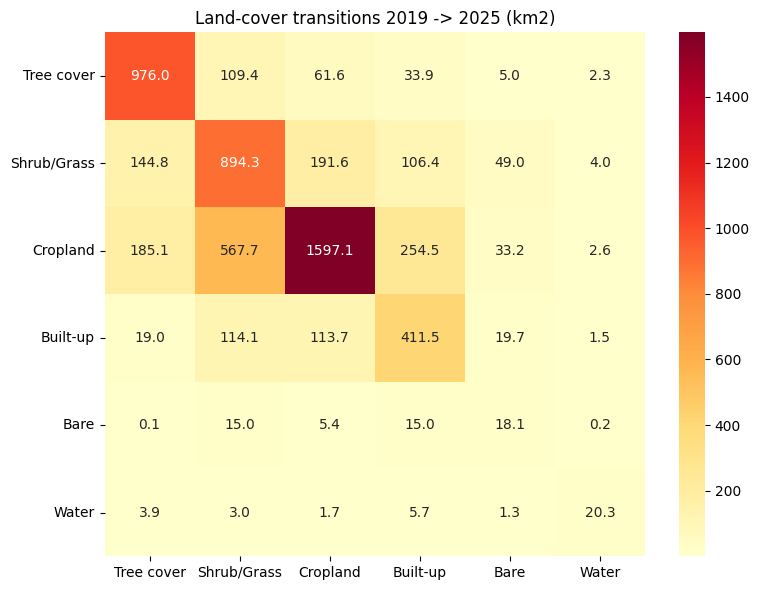

                2019     2025  change_km2  change_%
class                                              
Tree cover   1188.27  1329.42      141.14     11.88
Shrub/Grass  1390.06  1703.69      313.62     22.56
Cropland     2640.22  1971.09     -669.13    -25.34
Built-up      679.61   827.31      147.70     21.73
Bare           53.80   126.42       72.63    135.00
Water          35.99    30.91       -5.08    -14.12


In [59]:
DW_MAP = {0: 5, 1: 0, 2: 1, 3: 2, 4: 2, 5: 1, 6: 3, 7: 4}

def year_map(year):
    c = comp[year].select(FEATS)
    dw = (ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1').filterBounds(roi)
          .filterDate(f'{year}-01-01', f'{year}-04-30').select('label').mode())
    lab = dw.remap(list(DW_MAP.keys()), list(DW_MAP.values())).rename('label').clip(roi)
    s = c.addBands(lab).sample(region=roi, scale=30, numPixels=6000, seed=42, tileScale=4)
    clf_y = ee.Classifier.smileRandomForest(300, seed=42).train(s, 'label', FEATS)
    return c.classify(clf_y).rename('c')

map19 = year_map(2019)
map25 = year_map(2025)

def class_area(img):
    a = ee.Image.pixelArea().divide(1e6).addBands(img)
    g = a.reduceRegion(reducer=ee.Reducer.sum().group(groupField=1, groupName='c'), geometry=roi,
                       scale=30, maxPixels=1e11, bestEffort=True, tileScale=4).get('groups')
    d = pd.DataFrame(ee.List(g).getInfo()).rename(columns={'sum': 'km2'})
    d['class'] = d['c'].astype(int).map(dict(enumerate(CLASSES)))
    return d.set_index('class')['km2']

area = pd.DataFrame({'2019': class_area(map19), '2025': class_area(map25)}).fillna(0)
area['change_km2'] = area['2025'] - area['2019']
area['change_%'] = area['change_km2'] / area['2019'] * 100
area = area.round(2)
area.to_csv('results/area_change.csv')

area[['2019', '2025']].plot.bar(figsize=(8, 4.5), title='Land-cover area, Rawalpindi district (km2)')
plt.ylabel('km2'); plt.tight_layout(); plt.savefig('results/area_change.png', dpi=200); plt.show()

t_img = map19.multiply(10).add(map25).rename('t')
a = ee.Image.pixelArea().divide(1e6).addBands(t_img)
g = a.reduceRegion(reducer=ee.Reducer.sum().group(groupField=1, groupName='t'), geometry=roi,
                   scale=30, maxPixels=1e11, bestEffort=True, tileScale=4).get('groups')
T = pd.DataFrame(ee.List(g).getInfo())
T['from'] = (T.t // 10).astype(int); T['to'] = (T.t % 10).astype(int)
tm = T.pivot_table(index='from', columns='to', values='sum', aggfunc='sum').fillna(0)
tm.index = [CLASSES[i] for i in tm.index]; tm.columns = [CLASSES[i] for i in tm.columns]
plt.figure(figsize=(8, 6)); sns.heatmap(tm.round(1), annot=True, fmt='.1f', cmap='YlOrRd')
plt.title('Land-cover transitions 2019 -> 2025 (km2)'); plt.tight_layout()
plt.savefig('results/transition_matrix.png', dpi=200); plt.show()
tm.round(2).to_csv('results/transition_matrix.csv')

for yr, m in [(2019, map19), (2025, map25)]:
    u = m.visualize(min=0, max=5, palette=PALETTE).getThumbURL({'region': region, 'dimensions': 900, 'format': 'png'})
    rr = requests.get(u); open(f'results/lulc_{yr}.png', 'wb').write(rr.content)
print(area)

In [60]:
import shutil
from google.colab import files
shutil.make_archive('results_project2', 'zip', 'results')
files.download('results_project2.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 2. Automatic training labels (ESA WorldCover 2021)
WorldCover classes are merged into 6 classes: Tree cover, Shrub/Grass, Cropland, Built-up, Bare, Water. Other classes are ignored.

In [50]:
CLASSES = ['Tree cover', 'Shrub/Grass', 'Cropland', 'Built-up', 'Bare', 'Water']
wc = ee.ImageCollection('ESA/WorldCover/v200').first().select('Map')
label = wc.remap([10, 20, 30, 40, 50, 60, 80], [0, 1, 1, 2, 3, 4, 5]).rename('label').clip(roi)

stack = comp[2021].select(FEATS).addBands(label)
samples = stack.stratifiedSample(numPoints=600, classBand='label', region=roi, scale=20,
                                 seed=42, geometries=True, tileScale=4)
feats = samples.getInfo()['features']
S = pd.DataFrame([{**f['properties'], 'lon': f['geometry']['coordinates'][0],
                   'lat': f['geometry']['coordinates'][1]} for f in feats]).dropna()
S['label'] = S['label'].astype(int)
print(S.shape); print(S['label'].map(dict(enumerate(CLASSES))).value_counts())

(3600, 16)
label
Tree cover     600
Shrub/Grass    600
Cropland       600
Built-up       600
Bare           600
Water          600
Name: count, dtype: int64
(3600, 16)
label
Tree cover     600
Shrub/Grass    600
Cropland       600
Built-up       600
Bare           600
Water          600
Name: count, dtype: int64


## 3. Classifier benchmark: random CV vs spatial-block CV

In [51]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

X, y = S[FEATS].values, S['label'].values
# ~5 km spatial blocks: neighbouring pixels always stay in the same fold
blocks = (np.floor(S.lat / 0.05).astype(int).astype(str) + '_' + np.floor(S.lon / 0.05).astype(int).astype(str)).values
print('Spatial blocks:', len(set(blocks)))

models = {
    'RandomForest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1),
    'GradientBoosting': HistGradientBoostingClassifier(random_state=42),
    'SVM-RBF': make_pipeline(StandardScaler(), SVC(C=5, class_weight='balanced')),
}
rows, store = [], {}
for name, m in models.items():
    p_rand = cross_val_predict(m, X, y, cv=KFold(5, shuffle=True, random_state=42))
    p_spat = cross_val_predict(m, X, y, cv=GroupKFold(5), groups=blocks)
    store[name] = p_spat
    rows.append(dict(model=name,
                     acc_random_CV=accuracy_score(y, p_rand), F1macro_random_CV=f1_score(y, p_rand, average='macro'),
                     acc_spatial_CV=accuracy_score(y, p_spat), F1macro_spatial_CV=f1_score(y, p_spat, average='macro')))
bench = pd.DataFrame(rows).set_index('model').round(3)
bench['optimism_gap'] = (bench.acc_random_CV - bench.acc_spatial_CV).round(3)
bench.to_csv('results/classifier_benchmark.csv'); bench

Spatial blocks: 271


,acc_random_CV,F1macro_random_CV,acc_spatial_CV,F1macro_spatial_CV,optimism_gap
model,,,,,
RandomForest,0.755,0.755,0.751,0.751,0.004
GradientBoosting,0.751,0.751,0.749,0.750,0.002
SVM-RBF,0.782,0.783,0.779,0.780,0.003


Spatial blocks: 271


,acc_random_CV,F1macro_random_CV,acc_spatial_CV,F1macro_spatial_CV,optimism_gap
model,,,,,
RandomForest,0.755,0.755,0.751,0.751,0.004
GradientBoosting,0.751,0.751,0.749,0.750,0.002
SVM-RBF,0.782,0.783,0.779,0.780,0.003


Best (spatial CV): SVM-RBF


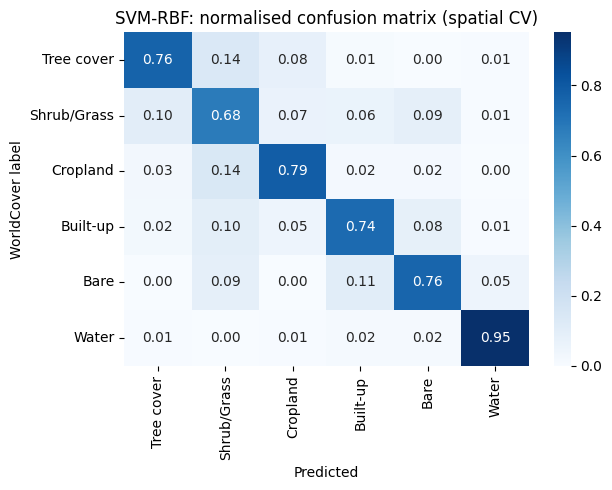

              precision    recall  f1-score   support

  Tree cover       0.83      0.76      0.79       600
 Shrub/Grass       0.59      0.68      0.63       600
    Cropland       0.79      0.79      0.79       600
    Built-up       0.77      0.74      0.76       600
        Bare       0.78      0.76      0.77       600
       Water       0.93      0.95      0.94       600

    accuracy                           0.78      3600
   macro avg       0.78      0.78      0.78      3600
weighted avg       0.78      0.78      0.78      3600

Best (spatial CV): SVM-RBF


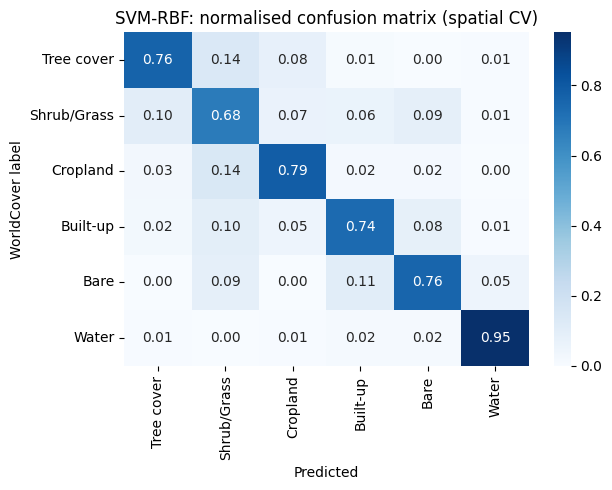

              precision    recall  f1-score   support

  Tree cover       0.83      0.76      0.79       600
 Shrub/Grass       0.59      0.68      0.63       600
    Cropland       0.79      0.79      0.79       600
    Built-up       0.77      0.74      0.76       600
        Bare       0.78      0.76      0.77       600
       Water       0.93      0.95      0.94       600

    accuracy                           0.78      3600
   macro avg       0.78      0.78      0.78      3600
weighted avg       0.78      0.78      0.78      3600



In [52]:
best = bench['F1macro_spatial_CV'].idxmax(); print('Best (spatial CV):', best)
present = sorted(set(y))
cm = confusion_matrix(y, store[best], labels=present, normalize='true')
plt.figure(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=[CLASSES[i] for i in present],
            yticklabels=[CLASSES[i] for i in present])
plt.title(f'{best}: normalised confusion matrix (spatial CV)'); plt.ylabel('WorldCover label'); plt.xlabel('Predicted')
plt.tight_layout(); plt.savefig('results/confusion_matrix.png', dpi=200); plt.show()
print(classification_report(y, store[best], labels=present, target_names=[CLASSES[i] for i in present]))

## 4. Map 2019 and 2025 with Earth Engine's Random Forest
The benchmark above runs locally in scikit-learn. For wall-to-wall mapping, a Random Forest is trained on the same samples **inside Earth Engine** so the whole district can be classified without downloads.
Note: the classifier is trained on 2021 and applied to 2019/2025, so small year-to-year spectral shifts are a limitation (discussed in the write-up).

2019


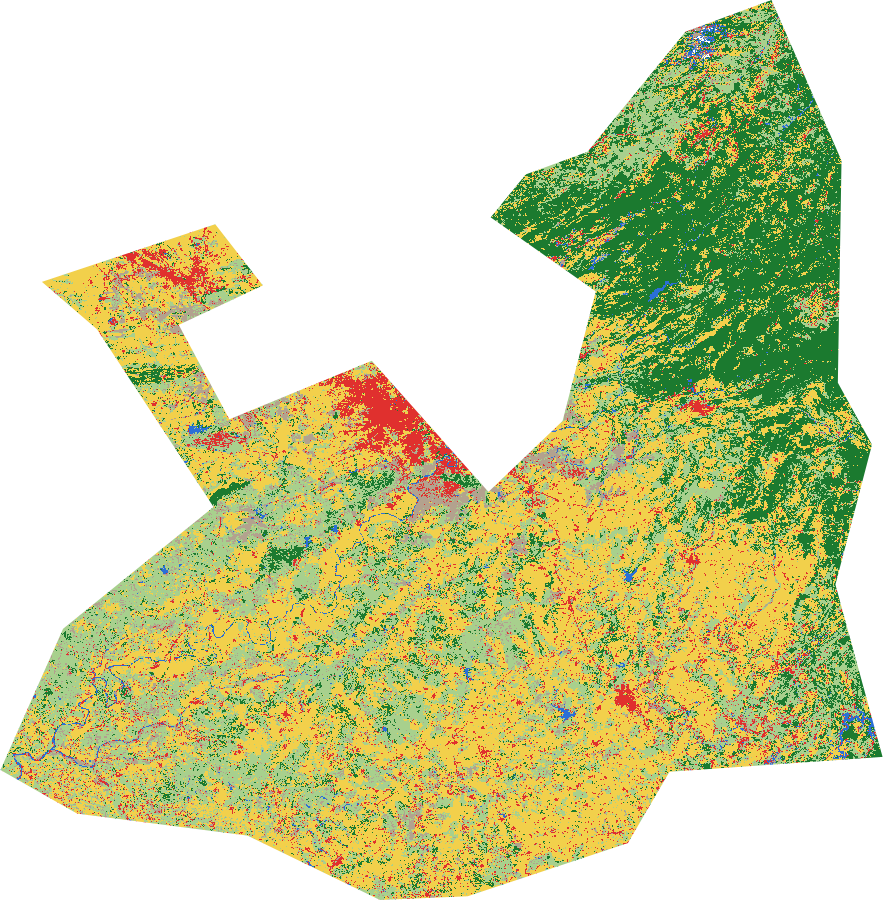

2025


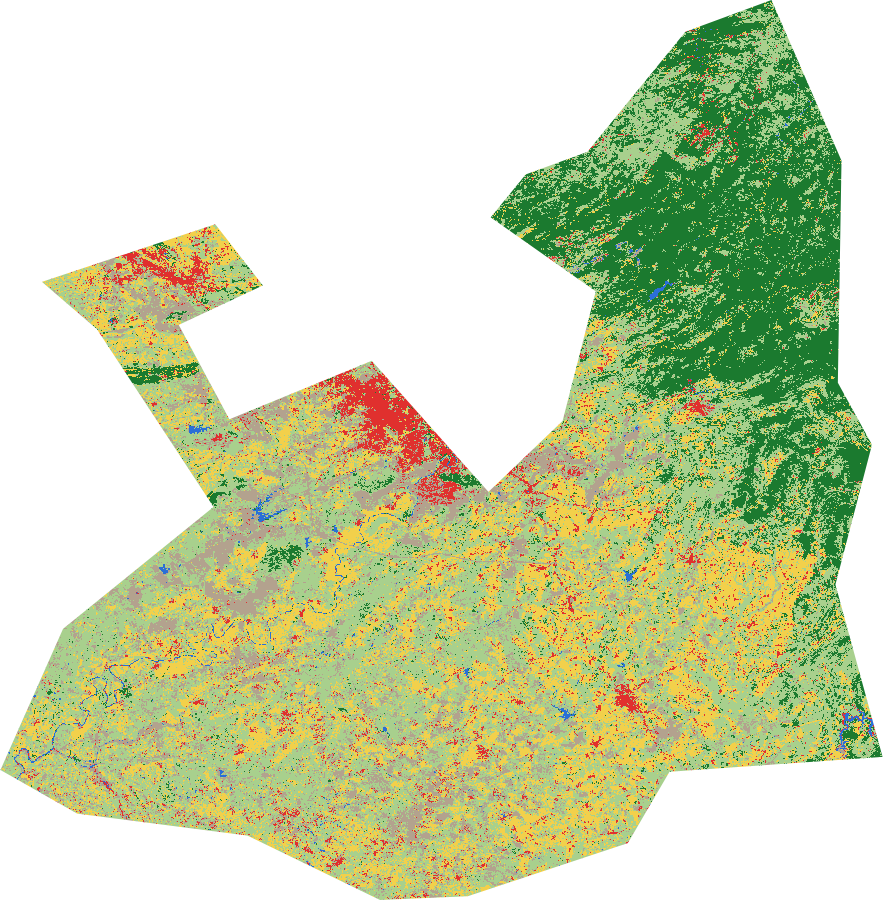

Legend: {'Tree cover': '1b7a2f', 'Shrub/Grass': 'a8d08d', 'Cropland': 'f2d04b', 'Built-up': 'e0302e', 'Bare': 'b3a28e', 'Water': '2b6fd6'}
2019


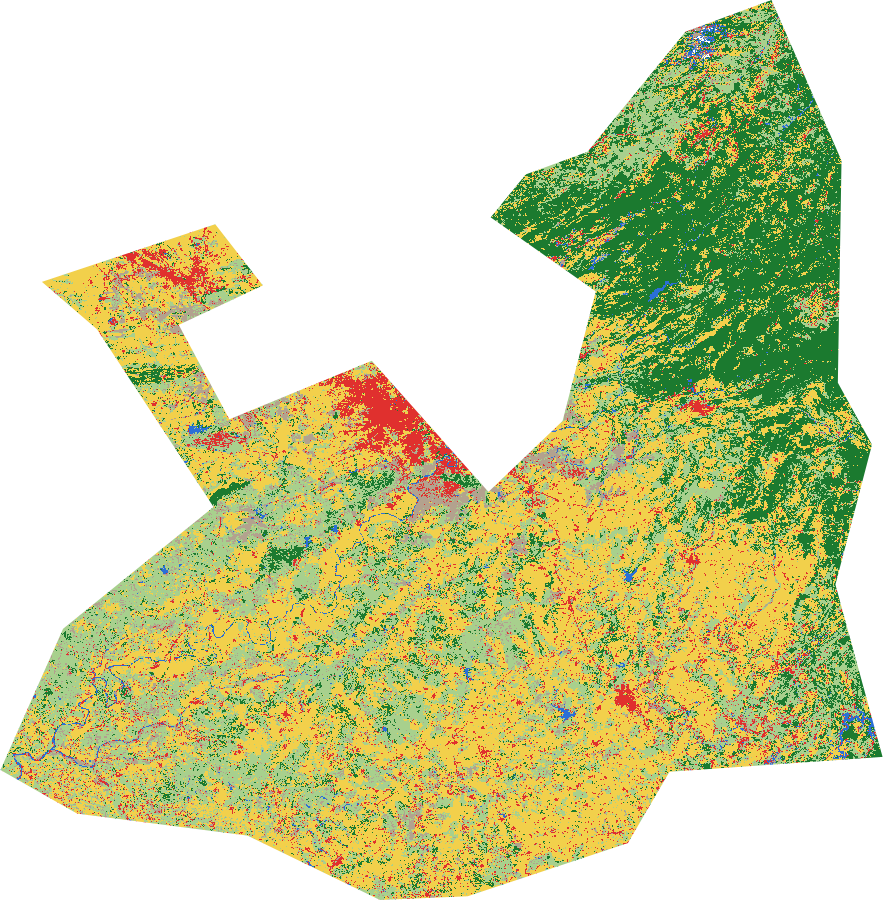

2025


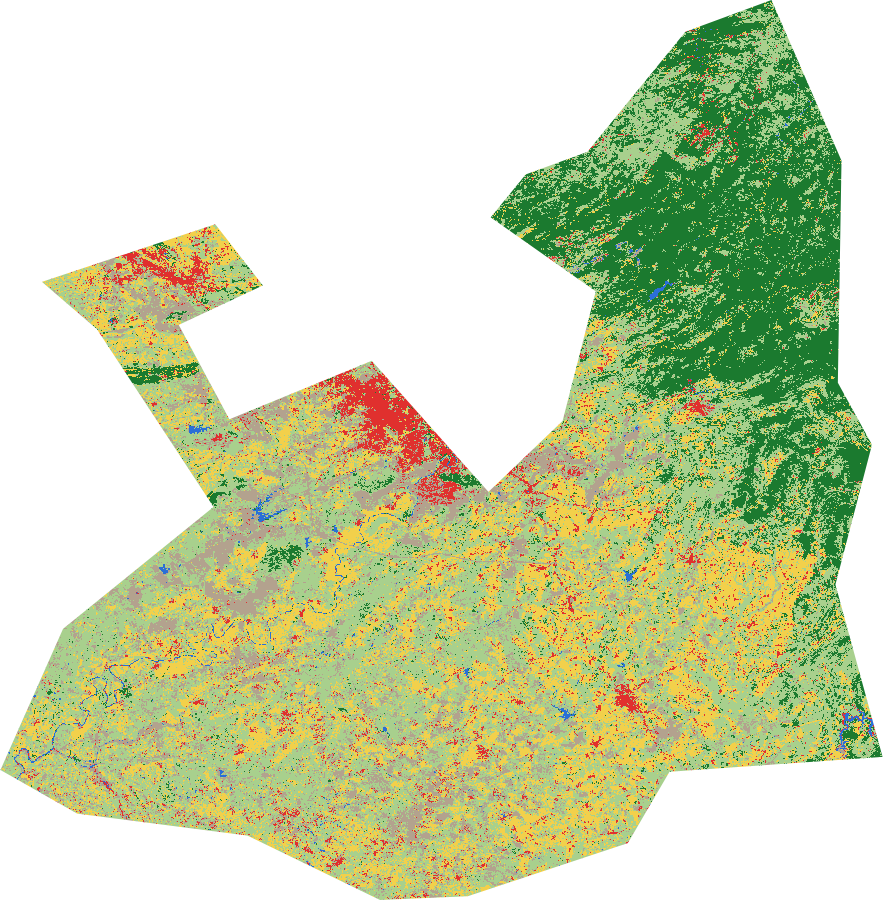

Legend: {'Tree cover': '1b7a2f', 'Shrub/Grass': 'a8d08d', 'Cropland': 'f2d04b', 'Built-up': 'e0302e', 'Bare': 'b3a28e', 'Water': '2b6fd6'}


In [53]:
fc_train = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([r.lon, r.lat]), {**{k: float(r[k]) for k in FEATS}, 'label': int(r.label)})
                                 for _, r in S.iterrows()])
clf = ee.Classifier.smileRandomForest(300, seed=42).train(fc_train, 'label', FEATS)
map19 = comp[2019].select(FEATS).classify(clf).rename('c')
map25 = comp[2025].select(FEATS).classify(clf).rename('c')

PALETTE = ['1b7a2f', 'a8d08d', 'f2d04b', 'e0302e', 'b3a28e', '2b6fd6']
vis = {'min': 0, 'max': 5, 'palette': PALETTE}
region = roi.bounds()
for yr, m in [(2019, map19), (2025, map25)]:
    url = m.visualize(**vis).getThumbURL({'region': region, 'dimensions': 900, 'format': 'png'})
    r = requests.get(url); open(f'results/lulc_{yr}.png', 'wb').write(r.content)
    print(yr); display(Image(r.content))
print('Legend:', dict(zip(CLASSES, PALETTE)))

## 5. Area statistics, urban growth and transitions

In [54]:
url = map25.visualize(**vis).getThumbURL({'region': region, 'dimensions': 600, 'format': 'png'})
r = requests.get(url)
print(r.status_code, r.headers.get('content-type'))
print(r.content[:400])
n = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED').filterBounds(roi).filterDate('2025-01-01','2025-12-31').size().getInfo()
print('Sentinel-2 images in 2025:', n)

200 image/png
b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x02M\x00\x00\x02X\x08\x06\x00\x00\x00\x7f\xe1\xd2p\x00\x00\x80\x00IDATx^\xec\xbd\t\xb4\xaeYU\x9ek\x15\x14\x05\x94\x82\x82 \xe4\x08\x8ab\x03HcWj4\x01\xfb\xa8IlrUbb\x17M\x8c^s\xd1DCb\xdfG\x89\xa2\x12\x8c\xc6\x9bkC\x8c\x1ec\x17\xe1\xc6x\x1d\x12e\xa8h4\x12DA\x14\xc1BDP\x14\xa5,\xda\xa2*w\xaes\xfe\xf7\xe4=\xcf\x99k}\xeb\xfb\x9b\xdd\xcew\x8cw|\xdf\x9ak\xce\xb9\xfa5\xe7\xf9\xf7>\xff~\x8b\xb7(\x14\n\x85B\xa1p\xaep\xe1K\x1e}}\xf0\xc3\x82O\x0b\xfe0\xeb\x0b\x85B\xa1P(\x14\xce5"AzX\xf0_\x05_\x16\xfc_\x1b\xde\x11|(u\x0b\x85B\xa1P(\x14\xce\x15"!z\xdb\xe0\xe7\x07\x7fU\x89\xd2\xc5\xe7~\x8b\x12\xa6\xffu\xebs?\xa6\x95\x9fB\xbbB\xa1P(\x14\n\x853\x8fH\x86\xee\x16\xfc\x84\xe0O\x04\xdfh\x9f*]\xc5\x96<mxk\x94\xefM?\x85B\xa1P(\x14\ng\x12\xb7>\xf7c\xde/\x92\x9f\xef\x08\xfe)\x13$\xd2\x12&\xf1\x0b\xe9\xafP(\x14\n\x85B\xe1\xcc \x12\xa0\x07\x05\xbf$\xf8B&F=*Q\xf2r<_\x12\xbc\x9e\xfe\x0b\x85B\xa1P(\x14N-"\xb9\xb9)\xf8\xe9\xc1g\x06\xefdR\xb4-#y\xfa8\xb6U(\x1

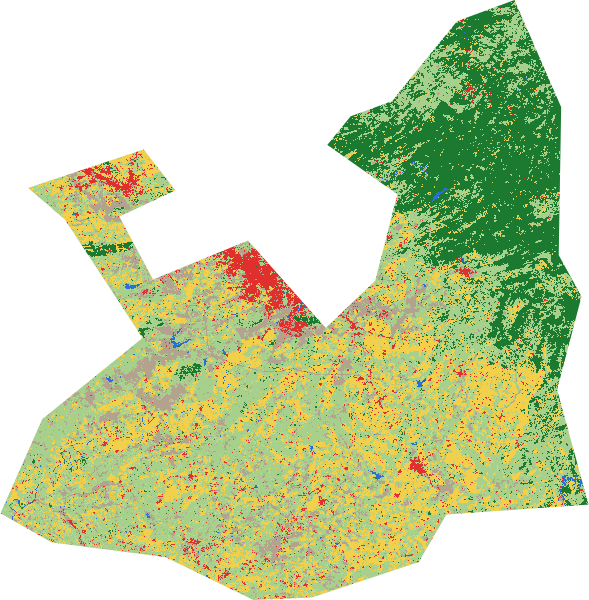

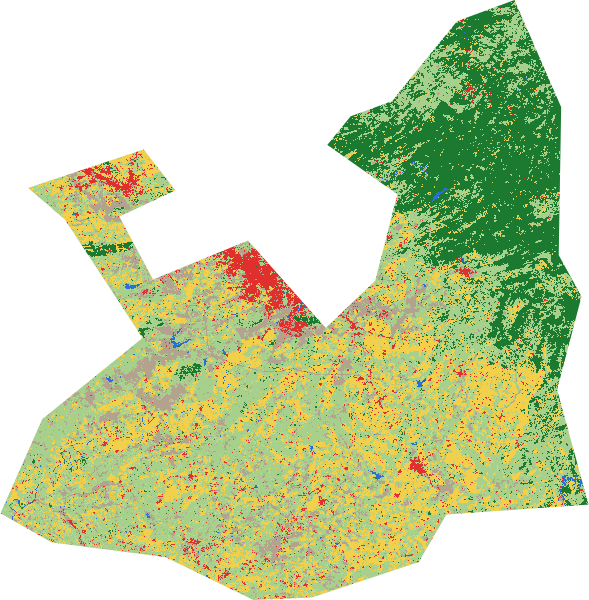

In [55]:
open('results/lulc_2025.png', 'wb').write(r.content)
display(Image(r.content))

In [56]:
def class_area(img):
    a = ee.Image.pixelArea().divide(1e6).addBands(img)
    g = a.reduceRegion(reducer=ee.Reducer.sum().group(groupField=1, groupName='c'), geometry=roi,
                       scale=30, maxPixels=1e11, bestEffort=True, tileScale=4).get('groups')
    d = pd.DataFrame(ee.List(g).getInfo()).rename(columns={'sum': 'km2'})
    d['class'] = d['c'].astype(int).map(dict(enumerate(CLASSES))); return d.set_index('class')['km2']

area = pd.DataFrame({'2019': class_area(map19), '2025': class_area(map25)}).fillna(0)
area['change_km2'] = area['2025'] - area['2019']
area['change_%'] = (area['change_km2'] / area['2019'] * 100)
area = area.round(2); area.to_csv('results/area_change.csv'); area

,2019,2025,change_km2,change_%
class,,,,
Tree cover,1445.60,1246.25,-199.35,-13.79
Shrub/Grass,1589.88,2344.41,754.54,47.46
Cropland,2105.43,1214.74,-890.69,-42.30
Built-up,455.94,346.58,-109.37,-23.99
Bare,315.78,791.48,475.70,150.64
Water,75.31,45.36,-29.95,-39.77


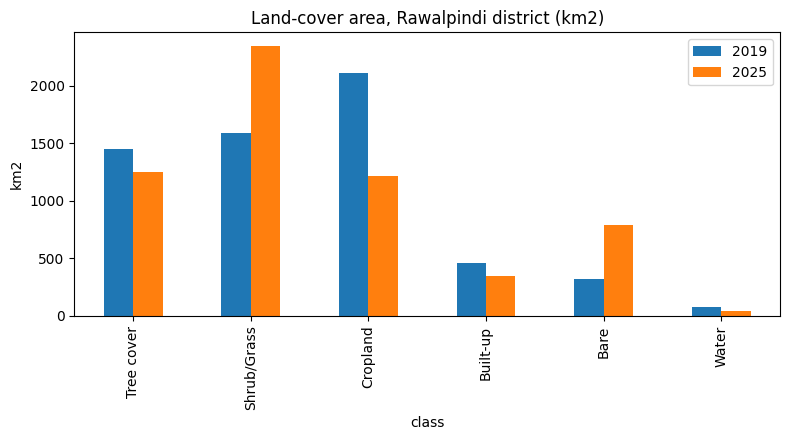

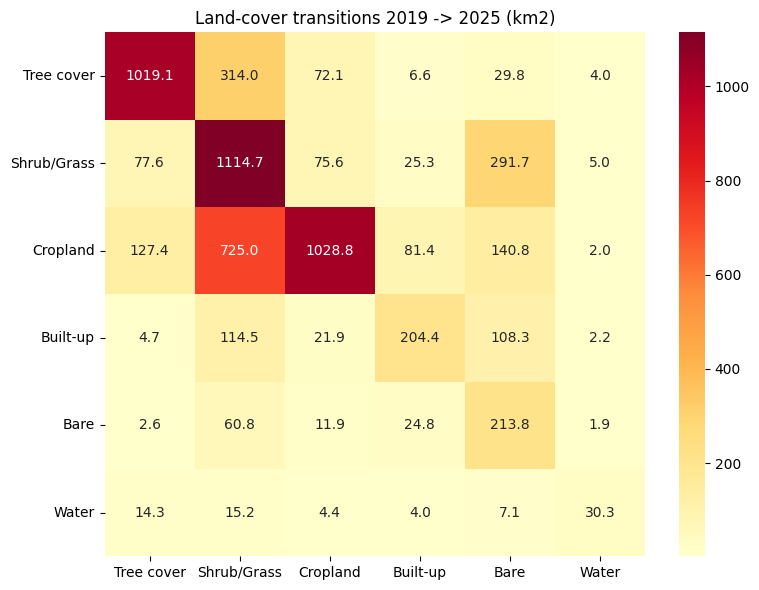

Sources of new built-up land (km2):
Cropland       81.39
Shrub/Grass    25.25
Bare           24.82
Tree cover      6.60
Water           4.03
Name: Built-up, dtype: float64


In [57]:
area[['2019', '2025']].plot.bar(figsize=(8, 4.5), title='Land-cover area, Rawalpindi district (km2)')
plt.ylabel('km2'); plt.tight_layout(); plt.savefig('results/area_change.png', dpi=200); plt.show()

# Transition matrix (from 2019 -> to 2025)
code_img = map19.multiply(10).add(map25).rename('t')
a = ee.Image.pixelArea().divide(1e6).addBands(code_img)
g = a.reduceRegion(reducer=ee.Reducer.sum().group(groupField=1, groupName='t'), geometry=roi,
                   scale=30, maxPixels=1e11, bestEffort=True, tileScale=4).get('groups')
T = pd.DataFrame(ee.List(g).getInfo()); T['from'] = (T.t // 10).astype(int); T['to'] = (T.t % 10).astype(int)
tm = T.pivot_table(index='from', columns='to', values='sum', aggfunc='sum').fillna(0)
tm.index = [CLASSES[i] for i in tm.index]; tm.columns = [CLASSES[i] for i in tm.columns]
plt.figure(figsize=(8, 6)); sns.heatmap(tm.round(1), annot=True, fmt='.1f', cmap='YlOrRd')
plt.title('Land-cover transitions 2019 -> 2025 (km2)'); plt.tight_layout()
plt.savefig('results/transition_matrix.png', dpi=200); plt.show()
tm.round(2).to_csv('results/transition_matrix.csv')
gain = tm.loc[[c for c in tm.index if c != 'Built-up'], 'Built-up'].sort_values(ascending=False)
print('Sources of new built-up land (km2):'); print(gain.round(2))